# Create a graph from interacting with Chris's MussBuss game

In [130]:
import networkx as nx
from requests import Session
import pandas as pd
import time
from mussbot.mussbot import Player
import matplotlib.pyplot as plt
from collections import Counter


FS = 15

In [2]:
%load_ext autoreload
%autoreload 2

# Muss Buss

### Create the player clients

In [4]:
kwargs = dict(host='http://localhost:8080', game_number=None, wait=0.0, verbose=False)
p1 = Player(username='john', password='123', **kwargs)
p2 = Player(username='chris', password='123', **kwargs)

### Play a game

In [73]:
def get_edges_from_nodes(nodes):
    edges = []
    for i in range(len(nodes) - 1):
        edges.append(tuple(nodes[i:i + 2]))
    return edges

In [152]:
state_name_mappings = {
    'invalidDraw-True_invalidRoll-True_invalidStop-True_invalidPass-True_invalidHolds-False': 'HOLD',
    'invalidDraw-True_invalidRoll-False_invalidStop-True_invalidPass-True_invalidHolds-True': 'ROLL',
    'invalidDraw-False_invalidRoll-True_invalidStop-True_invalidPass-False_invalidHolds-True': 'DRAW_INHERIT',
    'invalidDraw-True_invalidRoll-False_invalidStop-False_invalidPass-True_invalidHolds-True_invalidHold-True': 'STOP',
    'invalidDraw-False_invalidRoll-True_invalidStop-True_invalidPass-True_invalidHolds-True': 'DRAW_FRESH',
    'invalidDraw-True_invalidRoll-False_invalidStop-True_invalidPass-True_invalidHolds-True_invalidHold-True': 'ROLL',
    'invalidDraw-False_invalidRoll-True_invalidStop-False_invalidPass-True_invalidHolds-True_invalidHold-True': 'FILL',
    'invalidDraw-False_invalidRoll-False_invalidStop-True_invalidPass-True_invalidHolds-True': 'VENGEANCE'
}

In [156]:
def check_if_players_are_in_same_game(players):
    msg = 'These players are not part of the same game.'
    assert len(set(player.game_number for player in players)) == 1, msg

def get_winner(players):
    check_if_players_are_in_same_game(players)
    for player in players[0].game.players:
        if player['winner']:
            return player['name']
    return False

def get_valid_actions(invalid_actions):
    return {key.lstrip('in'): val == False for key, val in invalid_actions.items()}

def get_state_name(invalid_actions):
    # valid_actions = get_valid_actions(invalid_actions)
    name = '_'.join([f'{key}-{val}' for key, val in invalid_actions.items()])
    return name

def play_a_game(*players):
    '''
    Plays a game of Muss Buss.
    '''
    node_lists = [[] for i in range(len(players))]
    t0 = time.time()
    print('Starting the game.')
    n = 0
    while not get_winner(players):
        for player, nodes in zip(players, node_lists):
            player.take_turn()
            state = get_state_name(player.game.invalid_actions)
            nodes.append(state)
            n += 1
    winner = get_winner(players)
    elapsed = (time.time() - t0)
    tps = n / elapsed
    msg = f'{winner} won!\n\nTime elapsed: {elapsed:.1f} seconds\nTotal turns: {n}\nTurns per second: {tps: .1f}'
    print(msg)
    return node_lists

#### Start a new game

In [154]:
p1.new_game(['john', 'chris'])
p2.switch_games(p1.game_number)
print(p1)
print(p2)

(john) <GAME_16>: john, chris
(chris) <GAME_16>: john, chris


In [155]:
node_lists = play_a_game(p1, p2)
for nl in node_lists:
    nl = list(map(state_name_mappings.get, nl))

Starting the game.
chris won!

Time elapsed: 31.5 seconds
Total turns: 472
Turns per second:  15.0


In [215]:
weights = {}
for edge in get_edges_from_nodes(nodes):
    weights.setdefault(edge[0], []).append(edge[1])
for key, val in weights.items():
    weights[key] = Counter(val)

In [216]:
weights

{'ROLL': Counter({'HOLD': 61, 'DRAW_FRESH': 20}),
 'HOLD': Counter({'STOP': 31, 'ROLL': 28, 'FILL': 2}),
 'STOP': Counter({'DRAW_INHERIT': 31}),
 'DRAW_INHERIT': Counter({'ROLL': 28, 'DRAW_FRESH': 4}),
 'DRAW_FRESH': Counter({'ROLL': 23, 'DRAW_FRESH': 3, 'VENGEANCE': 1}),
 'FILL': Counter({'DRAW_INHERIT': 2}),
 'VENGEANCE': Counter({'ROLL': 1})}

In [207]:
Counter(get_edges_from_nodes(nodes))

Counter({('ROLL', 'HOLD'): 61,
         ('HOLD', 'STOP'): 31,
         ('STOP', 'DRAW_INHERIT'): 31,
         ('DRAW_INHERIT', 'ROLL'): 28,
         ('ROLL', 'DRAW_FRESH'): 20,
         ('DRAW_FRESH', 'ROLL'): 23,
         ('HOLD', 'ROLL'): 28,
         ('DRAW_FRESH', 'DRAW_FRESH'): 3,
         ('DRAW_INHERIT', 'DRAW_FRESH'): 4,
         ('HOLD', 'FILL'): 2,
         ('FILL', 'DRAW_INHERIT'): 2,
         ('DRAW_FRESH', 'VENGEANCE'): 1,
         ('VENGEANCE', 'ROLL'): 1})

In [166]:
G = nx.DiGraph()
for node in node_lists:
    G.add_edges_from(get_edges_from_nodes(nodes))

In [ ]:
pos = nx.drawing.nx_pydot.graphviz_layout(G, prog='dot')
nx.draw_networkx(G, pos)

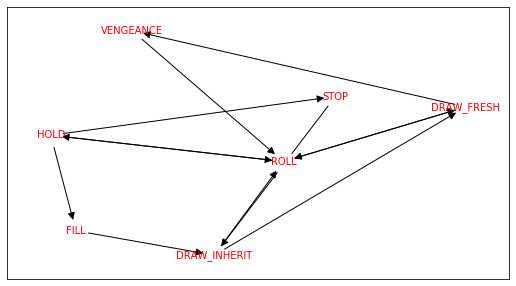

In [199]:
fig, ax = plt.subplots(figsize=(9, 5))
kwargs = dict(arrowsize=15,
              node_size=500,
              node_color='w',
              font_weight='regular',
              font_color='r',
              font_size=10)
# pos = nx.spring_layout(G, iterations=5)
nx.draw_networkx(G, pos=pos, ax=ax, **kwargs)
plt.show()

In [195]:
G.nodes

NodeView(('ROLL', 'HOLD', 'STOP', 'DRAW_INHERIT', 'DRAW_FRESH', 'FILL', 'VENGEANCE'))

In [194]:
1000 * nx.directed_laplacian_matrix(G) // 10

matrix([[100., -48.,   0., -15., -42.,   0., -29.],
        [-48., 100., -29.,   0.,   0., -29.,   0.],
        [  0., -29., 100., -36.,   0.,   0.,   0.],
        [-15.,   0., -36., 100., -15., -36.,   0.],
        [-42.,   0.,   0., -15.,  66.,   0., -29.],
        [  0., -29.,   0., -36.,   0., 100.,   0.],
        [-29.,   0.,   0.,   0., -29.,   0., 100.]])